# INFO 2950 Project, Phase II: Exploratory Analysis and Preregistration
## Game lifecycles on Steam and Twitch

Group members: Suzie Ahn (sa2454) and Claire Moon (cm2276)

## Research Questions

**RQ1:** In the first 12 months after a game launches on Steam, how much of its launch-peak player base and Twitch audience does it keep? Does Twitch interest drop off faster or slower than Steam interest?

**RQ2:** Do multiplayer games and free-to-play games keep their players and viewers longer than other games?

After exploring the data, we narrowed RQ1 to a 12-month window after launch and changed how we measure Twitch interest. The reasons are explained at the end of the exploratory data analysis.

## Data Collection and Cleaning

### Data collection

We downloaded all of our raw files directly (no scraping or API keys needed): the Steam player counts and Twitch rankings from Kaggle, and the game information from the Steam Dataset 2025 on Zenodo. They are stored unchanged in `datasets/raw/`.

Raw data: https://drive.google.com/drive/folders/1OFW5YLaD6Xdiluj3ZBWWyv9GlY8sIWpo?usp=share_link

- `steamcharts.csv`: Kaggle, *Steam Monthly Average Players* (lunthu), from SteamCharts.com. One row per game per month, July 2012 to September 2025.
- `Twitch_game_data.csv`: Kaggle, *Evolution of Top Games on Twitch* (rankirsh), from SullyGnome.com. One row per game per month (top 200 only), January 2016 to September 2024.
- `applications.csv`, `categories.csv`, `application_categories.csv`: Steam Dataset 2025 (vintagedon, GitHub/Zenodo), from the Steam store, collected in 2025. One row per app, per category, and per (app, category) pair.

The Steam Dataset 2025 has many more files (genres, reviews, developers, and so on), but we only use these three because RQ2 only needs to know whether each game is multiplayer and whether it is free-to-play.

### Data cleaning

This section goes step by step from the raw files to our two analysis-ready files:
- `datasets/clean/games_analysis_ready.csv`: one row per game
- `datasets/clean/lifecycle_panel.csv`: one row per game per month since launch

We also save intermediate files along the way so we don't have to redo every step each time.

In [ ]:
# Connect Google Drive and move into the project folder (Colab)
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/INFO2950_Project')
print("datasets/raw contains:")
for name in os.listdir('datasets/raw'):
    print("   ", name)

Mounted at /content/drive
datasets/raw contains:
    Twitch_game_data.csv
    applications.csv
    categories.csv
    application_categories.csv
    steamcharts.csv


In [ ]:
# Imports used throughout the notebook
import io, re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RAW = Path("datasets/raw")      # raw files, unchanged
CLEAN = Path("datasets/clean")  # files we create
CLEAN.mkdir(parents=True, exist_ok=True)

#### Loading the raw files

Most of the Twitch game file is in UTF-8, but a few lines use a different text encoding (Windows-1252), so reading it the normal way either crashes or garbles names like "Pokémon". We read it line by line and use the other encoding only for the lines that need it.

In [ ]:
# Read the Twitch file one line at a time. A few lines aren't UTF-8,
# so for those we fall back to cp1252.
def read_mixed_encoding_csv(path):
    lines = []
    n_fallback = 0
    with open(path, "rb") as f:
        for raw_line in f:
            try:
                lines.append(raw_line.decode("utf-8"))
            except UnicodeDecodeError:
                lines.append(raw_line.decode("cp1252", errors="replace"))
                n_fallback += 1
    print(f"{path.name}: {n_fallback} line(s) read as cp1252")
    return pd.read_csv(io.StringIO("".join(lines)))

steam_raw = pd.read_csv(RAW / "steamcharts.csv")
twitch_raw = read_mixed_encoding_csv(RAW / "Twitch_game_data.csv")

for name, df in [("steam_raw", steam_raw), ("twitch_raw", twitch_raw)]:
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   columns:")
    for i in range(0, len(df.columns), 4):   # 4 column names per line
        print("     ", ", ".join(df.columns[i:i + 4]))

Twitch_game_data.csv: 3 line(s) read as cp1252
steam_raw: 612,265 rows, 7 columns
   columns:
      month, avg_players, gain, gain_percent
      peak_players, name, steam_appid
twitch_raw: 21,000 rows, 12 columns
   columns:
      Rank, Game, Month, Year
      Hours_watched, Hours_streamed, Peak_viewers, Peak_channels
      Streamers, Avg_viewers, Avg_channels, Avg_viewer_ratio


#### Cleaning the Steam player data

- Turn the text month (like "Sep-25") into a real date and sort each game's months in order.
- Check for missing values and duplicate game-months.
- Count months that SteamCharts skipped in the middle of a game's history. We leave these as missing, not zero, because a skipped month means "not recorded," not "nobody played."

In [ ]:
steam = steam_raw.copy()
# "Sep-25" -> 2025-09-01
steam["date"] = pd.to_datetime(steam["month"], format="%b-%y")
steam = steam.sort_values(["steam_appid", "date"]).reset_index(drop=True)

print("Missing values:", steam.isna().sum().sum())
n_dupes = steam.duplicated(["steam_appid", "date"]).sum()
print("Duplicate (game, month) rows:", n_dupes)
print("Months covered:", steam["date"].min().date(),
      "to", steam["date"].max().date())
print("Number of games:", steam["steam_appid"].nunique())
print("Largest AppID:", steam["steam_appid"].max())

# A gap of more than 32 days between rows means a month was skipped
gap_rows = steam.groupby("steam_appid")["date"].diff().dt.days > 32
n_gap_games = steam.loc[gap_rows, "steam_appid"].nunique()
print(f"Rows right after a skipped month: {gap_rows.sum():,} "
      f"across {n_gap_games:,} games")

Missing values: 0
Duplicate (game, month) rows: 0
Months covered: 2012-07-01 to 2025-09-01
Number of games: 6729
Largest AppID: 802870
Rows right after a skipped month: 15,005 across 3,486 games


Two things we found in this step:

1. **The Steam file stops at AppID 802,870.** Steam gives out AppIDs roughly in order, so most games released after about 2018 (Valheim, Cyberpunk 2077, Elden Ring) are missing. Dota 2 is also missing. A few later games, like Helldivers 2, show up because their AppID was reserved early.
2. **The first month a game appears is often not its launch month.** Many games show up on SteamCharts months before release with less than one average player (just the store page or developer testing). If we called that the launch, *Getting Over It* would look like it lost almost all its players right away. So we define the launch month as the first month with at least 20 average players and at least 1% of the game's highest month in its first 13 tracked months. The 1% cutoff is low on purpose so that games that grew after launch (like PUBG) keep the right launch month. We checked this rule against six launch dates we looked up by hand: five match exactly, and Phasmophobia is one month late because it launched late in September 2020 with few players.

In [ ]:
# Spot check: are some well-known later games in the file?
check_ids = {570: "Dota 2", 892970: "Valheim", 1091500: "Cyberpunk 2077",
             1245620: "Elden Ring", 553850: "Helldivers 2"}
present = set(steam["steam_appid"])
for appid, title in check_ids.items():
    status = "present" if appid in present else "MISSING"
    print(f"{title:15s} (AppID {appid}): {status}")

# Months since each game first appears
first_seen = steam.groupby("steam_appid")["date"].transform("min")
year_diff = steam["date"].dt.year - first_seen.dt.year
month_diff = steam["date"].dt.month - first_seen.dt.month
steam["months_tracked"] = year_diff * 12 + month_diff

# Launch month = first month with >= 20 players AND >= 1% of the
# game's highest month in its first 13 tracked months
early = steam[steam["months_tracked"] <= 12]
early_max = early.groupby("steam_appid")["avg_players"].max()
cutoff = 0.01 * steam["steam_appid"].map(early_max)
meets_rule = (steam["avg_players"] >= 20) & (steam["avg_players"] >= cutoff)
launch_month = steam[meets_rule].groupby("steam_appid")["date"].min()
launch_month = launch_month.rename("launch_month")

first_tracked = steam.groupby("steam_appid")["date"].min()
print("\nGames whose launch month is later than their first tracked month:",
      (launch_month != first_tracked.reindex(launch_month.index)).sum())

# Compare our rule to launch dates we looked up on Steam store pages
known = {578080: ("PUBG", "2017-03"),
         240720: ("Getting Over It", "2017-12"),
         294100: ("RimWorld", "2016-07"),
         394360: ("Hearts of Iron IV", "2016-06"),
         582010: ("Monster Hunter: World", "2018-08"),
         739630: ("Phasmophobia", "2020-09")}
for appid, (title, actual) in known.items():
    print(f"  {title:22s} first seen {first_tracked[appid]:%Y-%m} | "
          f"ours {launch_month[appid]:%Y-%m} | actual {actual}")

Dota 2          (AppID 570): MISSING
Valheim         (AppID 892970): MISSING
Cyberpunk 2077  (AppID 1091500): MISSING
Elden Ring      (AppID 1245620): MISSING
Helldivers 2    (AppID 553850): present

Games whose launch month is later than their first tracked month: 1973
  PUBG                   first seen 2017-03 | ours 2017-03 | actual 2017-03
  Getting Over It        first seen 2017-10 | ours 2017-12 | actual 2017-12
  RimWorld               first seen 2016-05 | ours 2016-07 | actual 2016-07
  Hearts of Iron IV      first seen 2016-04 | ours 2016-06 | actual 2016-06
  Monster Hunter: World  first seen 2018-08 | ours 2018-08 | actual 2018-08
  Phasmophobia           first seen 2020-10 | ours 2020-10 | actual 2020-09


#### Cleaning the Twitch data

- Drop the one row that has no game name and make a date column.
- Twitch got much bigger between 2016 and 2021 (see the plot below). So we divide each game's average viewers by the total average viewers of all 200 listed categories that month. We call this `viewer_share`. This way a 2021 game doesn't look more popular just because Twitch was bigger in 2021. The top 200 make up almost all Twitch viewing, so their total is a good stand-in for the size of Twitch.

In [ ]:
twitch = twitch_raw.dropna(subset=["Game"]).copy()
twitch["date"] = pd.to_datetime(
    dict(year=twitch["Year"], month=twitch["Month"], day=1))

print("Twitch months covered:", twitch["date"].min().date(),
      "to", twitch["date"].max().date())
print("Games listed per month:", twitch.groupby("date").size().unique())

# Total average viewers of the top 200 each month, then each game's share of it
monthly_total = twitch.groupby("date")["Avg_viewers"].sum()
twitch["month_total_viewers"] = twitch["date"].map(monthly_total)
twitch["viewer_share"] = twitch["Avg_viewers"] / twitch["month_total_viewers"]

Twitch months covered: 2016-01-01 to 2024-09-01
Games listed per month: [200 199]


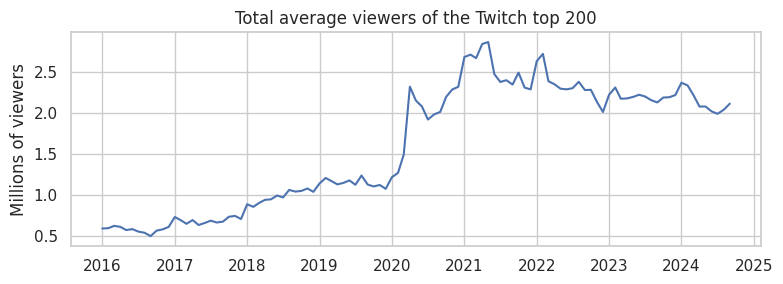

In [ ]:
# Total Twitch viewing over time
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(monthly_total.index, monthly_total / 1e6)
ax.set(title="Total average viewers of the Twitch top 200",
       ylabel="Millions of viewers")
plt.tight_layout()
plt.show()

#### Matching Twitch games to Steam games

The Twitch data only has game names, not Steam AppIDs, so we match on a cleaned-up version of the title:
- remove ™ ® © and apostrophes, remove accents, make everything lowercase, and turn other punctuation into spaces
- drop the 9 Steam titles that belong to more than one AppID, since we can't tell which one is meant
- add a short list of famous games that were renamed on Steam (for example, PLAYERUNKNOWN'S BATTLEGROUNDS is now "PUBG: BATTLEGROUNDS")
- skip general Twitch categories like Chess, Poker, and Music that happen to share a name with an unrelated Steam game

In [ ]:
def normalize_title(title):
    title = re.sub(r"[™®©]", "", str(title))   # remove trademark symbols
    title = re.sub(r"[’'`]", "", title)         # "Clancy's" -> "Clancys"
    # remove accents and make lowercase
    title = unicodedata.normalize("NFKD", title)
    title = title.encode("ascii", "ignore").decode().lower()
    title = re.sub(r"[^a-z0-9]", " ", title)     # other punctuation -> space
    return re.sub(r"\s+", " ", title).strip()

steam["title_key"] = steam["name"].map(normalize_title)
twitch["title_key"] = twitch["Game"].map(normalize_title)

# Drop Steam titles that map to more than one AppID
steam_titles = steam.drop_duplicates("steam_appid")
steam_titles = steam_titles[["steam_appid", "name", "title_key"]]
is_dupe = steam_titles["title_key"].duplicated(keep=False)
ambiguous = steam_titles.loc[is_dupe, "title_key"].unique()
safe_titles = steam_titles[~steam_titles["title_key"].isin(ambiguous)]
key_to_appid = safe_titles.set_index("title_key")["steam_appid"]
print("Ambiguous Steam titles dropped:", len(ambiguous))

# Games renamed on Steam after their Twitch years (checked by hand)
MANUAL_ALIASES = {
    "playerunknowns battlegrounds": 578080,   # now "PUBG: BATTLEGROUNDS"
    "counter strike global offensive": 730,   # now "Counter-Strike 2"
    "grand theft auto v": 271590,             # now "Grand Theft Auto V Legacy"
    "tom clancys rainbow six siege": 359550,  # now "... Siege X"
    "the witcher 3 wild hunt": 292030,        # Steam name is in Chinese here
    "hunt showdown": 594650,                  # now "Hunt: Showdown 1896"
    "black desert online": 582660,            # now "Black Desert"
}
NOT_A_GAME = {"chess", "poker", "slots", "music",
              "art", "sports", "retro", "casino"}

twitch["steam_appid"] = twitch["title_key"].map(key_to_appid)
aliases = twitch["title_key"].map(MANUAL_ALIASES)
twitch["steam_appid"] = twitch["steam_appid"].fillna(aliases)
twitch.loc[twitch["title_key"].isin(NOT_A_GAME), "steam_appid"] = np.nan

n_titles = twitch["title_key"].nunique()
n_matched = twitch.dropna(subset=["steam_appid"])["title_key"].nunique()
is_matched = twitch["steam_appid"].notna()
matched_viewers = twitch.loc[is_matched, "Avg_viewers"].sum()
share_matched = matched_viewers / twitch["Avg_viewers"].sum()
print(f"Twitch titles matched to Steam: {n_matched} of {n_titles} "
      f"({share_matched:.0%} of all top-200 viewing)")

Ambiguous Steam titles dropped: 9
Twitch titles matched to Steam: 657 of 2331 (23% of all top-200 viewing)


In [ ]:
# The most-watched Twitch titles that did NOT match (we checked these by hand)
unmatched = twitch[twitch["steam_appid"].isna()]
unmatched = unmatched.groupby("Game")["Avg_viewers"].sum()
unmatched = unmatched.sort_values(ascending=False)
for name in unmatched.head(25).index:
    print(name)

Just Chatting
League of Legends
Fortnite
VALORANT
Dota 2
Minecraft
World of Warcraft
Call of Duty: Warzone
Apex Legends
Hearthstone
Overwatch
Slots
Teamfight Tactics
Music
Escape from Tarkov
Special Events
Sports
Escape From Tarkov
IRL
Among Us
Overwatch 2
Destiny 2
Talk Shows & Podcasts
ASMR
Genshin Impact


Almost all of the big unmatched titles are not on Steam (League of Legends, Fortnite, VALORANT, Minecraft, World of Warcraft), are not games (Just Chatting, IRL, ASMR), or are missing from the Steam file because of the AppID cutoff (Dota 2, Apex Legends). So the low match rate (about 23% of viewing) mostly happens because the most-watched Twitch games aren't on Steam, not because our matching failed.

In [ ]:
# Keep matched rows. If two Twitch names map to the same game in a
# month, keep the bigger one.
twitch_matched = (twitch.dropna(subset=["steam_appid"])
                  .astype({"steam_appid": int})
                  .sort_values("Avg_viewers", ascending=False)
                  .drop_duplicates(["steam_appid", "date"]))

steam.to_csv(CLEAN / "steam_monthly_clean.csv", index=False)
twitch_matched.to_csv(CLEAN / "twitch_monthly_matched.csv", index=False)
print("Saved steam_monthly_clean.csv and twitch_monthly_matched.csv")

Saved steam_monthly_clean.csv and twitch_monthly_matched.csv


#### Building the month-by-month table

For each matched game we line up months 0 through 12 after its Steam launch. We only keep games that launched between January 2016 (when the Twitch data starts) and September 2023, so that all 12 follow-up months are inside the Twitch data.

In [ ]:
HORIZON = 12
WINDOW_START = pd.Timestamp("2016-01-01")
WINDOW_END = twitch["date"].max() - pd.DateOffset(months=HORIZON)

# Games launched in the window that appear on Twitch at least once
in_window = (launch_month >= WINDOW_START) & (launch_month <= WINDOW_END)
candidates = launch_month[in_window]
candidates = candidates[candidates.index.isin(twitch_matched["steam_appid"])]

steam_by_game = steam.set_index(["steam_appid", "date"])["avg_players"]
twitch_by_game = twitch_matched.set_index(["steam_appid", "date"])
twitch_by_game = twitch_by_game["viewer_share"]

rows = []
for appid, launch in candidates.items():
    months = pd.date_range(launch, periods=HORIZON + 1, freq="MS")
    for k, month in enumerate(months):
        rows.append({
            "steam_appid": appid,
            "months_since_launch": k,
            "date": month,
            # missing = SteamCharts skipped the month
            "steam_avg_players": steam_by_game.get((appid, month), np.nan),
            # missing = not in Twitch top 200
            "twitch_share": twitch_by_game.get((appid, month), np.nan),
        })
panel = pd.DataFrame(rows)
panel["on_twitch_list"] = panel["twitch_share"].notna()
print("Games:", len(candidates), "| rows:", len(panel))

Games: 442 | rows: 5746


#### Defining retention and building the one-row-per-game table

- **Launch peak:** the highest value in months 0 to 2. We use three months because month 0 is often only a partial month.
- **Retention in month k:** the value in month k divided by the launch peak. For example, 0.25 means 25% of the launch-peak interest is left. Values above 1 mean the game grew.
- **Which games we keep:** the game has to be in the Twitch top 200 at least once in months 0 to 2 (otherwise there's no Twitch launch to compare to), and its Steam launch peak has to be at least 100 average players. Below that, the ratios jump around a lot, and when we looked at these games many were re-releases of console games or name mix-ups.
- **When a game is off the Twitch list,** its Twitch retention is left missing because we don't know its viewership.
- **Months on Twitch list:** how many of months 0 to 12 the game was in the top 200. We always know this value, even when the game drops out.

In [ ]:
# Launch-window peaks (months 0-2)
launch = (panel[panel["months_since_launch"] <= 2]
          .groupby("steam_appid")
          .agg(steam_launch_peak=("steam_avg_players", "max"),
               twitch_launch_peak=("twitch_share", "max")))

print("Matched games launched in window:", len(launch))
launch = launch[launch["twitch_launch_peak"].notna()]
print("...and in Twitch top 200 in months 0-2:", len(launch))
launch = launch[launch["steam_launch_peak"] >= 100]
print("...and Steam launch peak >= 100 players:", len(launch))

lifecycle = panel.merge(launch, left_on="steam_appid", right_index=True)
lifecycle["steam_retention"] = (lifecycle["steam_avg_players"]
                                / lifecycle["steam_launch_peak"])
lifecycle["twitch_retention"] = (lifecycle["twitch_share"]
                                 / lifecycle["twitch_launch_peak"])

names = steam_titles.set_index("steam_appid")["name"]
lifecycle.insert(1, "name", lifecycle["steam_appid"].map(names))
lifecycle.to_csv(CLEAN / "lifecycle_panel.csv", index=False)

Matched games launched in window: 442
...and in Twitch top 200 in months 0-2: 373
...and Steam launch peak >= 100 players: 347


In [ ]:
# One row per game
def at_month(col, k):
    rows_k = lifecycle[lifecycle["months_since_launch"] == k]
    return rows_k.set_index("steam_appid")[col]

games = launch.copy()
games.insert(0, "name", games.index.map(names))
games["launch_month"] = launch_month.reindex(games.index)
for k in [1, 3, 6, 12]:
    games[f"steam_ret_m{k}"] = at_month("steam_retention", k)
    # Twitch retention is missing if the game was off the list
    games[f"twitch_ret_m{k}"] = at_month("twitch_retention", k)
    games[f"on_twitch_m{k}"] = at_month("on_twitch_list", k)
# out of 13 months (months 0 to 12)
games["months_on_twitch_list"] = (
    lifecycle.groupby("steam_appid")["on_twitch_list"].sum())

#### Adding game information from the Steam Dataset 2025

For RQ2 we need to know whether each game is multiplayer and whether it is free-to-play. Both come from the Steam Dataset 2025, which uses the same Steam AppID as our data, so we can join on AppID with no name matching.

- `applications.csv` is very large (mostly long text like game descriptions), so we only load the three columns we need.
- `categories.csv` lists Steam's category names (like "Single-player" or "Online PvP"), and `application_categories.csv` says which categories each game has.
- Some category names are stored in other languages. We only use the English names, which cover about 99% of games on Steam. If a game has no English game-mode label (for example, Counter-Strike 2, whose labels are stored in Arabic), we mark it as missing instead of guessing.
- `multiplayer` = 1 if the game has any multiplayer category, and 0 if it only has "Single-player".

In [ ]:
# Only the columns we need from the large applications file
apps = pd.read_csv(RAW / "applications.csv",
                   usecols=["appid", "type", "is_free"])
print("Apps:", len(apps))

categories = pd.read_csv(RAW / "categories.csv")
app_categories = pd.read_csv(RAW / "application_categories.csv")
app_categories = app_categories.merge(categories,
                                      left_on="category_id", right_on="id")

MULTIPLAYER = ["Multi-player", "Online PvP", "Online Co-op", "PvP", "Co-op",
               "LAN PvP", "LAN Co-op",
               "Shared/Split Screen", "Shared/Split Screen PvP",
               "Shared/Split Screen Co-op",
               "Cross-Platform Multiplayer", "MMO"]
app_categories["is_multiplayer"] = app_categories["name"].isin(MULTIPLAYER)
app_categories["is_single"] = app_categories["name"] == "Single-player"

# One row per game: does it have a multiplayer category? Single-player?
modes = app_categories.groupby("appid")[["is_multiplayer", "is_single"]].max()
modes["multiplayer"] = modes["is_multiplayer"].astype(int)

# Games with no English game-mode label at all (e.g. labels stored in
# Arabic) are marked missing, not 0
no_label = ~(modes["is_multiplayer"] | modes["is_single"])
modes.loc[no_label, "multiplayer"] = np.nan

is_free = apps["is_free"].astype(str).str.lower() == "true"
apps["free_to_play"] = is_free.astype(int)
info = apps.set_index("appid")[["type", "free_to_play"]]
info = info.join(modes["multiplayer"])

Apps: 239664


In [ ]:
# Join onto our games by Steam AppID
games = games.join(info)
print("Our games found in the Steam Dataset 2025:",
      games["type"].notna().sum(), "of", len(games))
print("Games with no English game-mode category:",
      games["multiplayer"].isna().sum())

games.to_csv(CLEAN / "games_analysis_ready.csv")
print(games.shape)

# Preview a few of the most important columns
preview_cols = ["name", "steam_ret_m3", "months_on_twitch_list",
                "multiplayer", "free_to_play"]
games[preview_cols].head()

Our games found in the Steam Dataset 2025: 333 of 347
Games with no English game-mode category: 19
(347, 20)


,name,steam_ret_m3,months_on_twitch_list,multiplayer,free_to_play
steam_appid,,,,,
115800,Owlboy,0.207317,1,0.0,0.0
210970,The Witness,0.146578,2,0.0,0.0
223100,Homefront®: The Revolution,0.359894,1,1.0,0.0
236870,HITMAN™,0.422247,8,0.0,0.0
240720,Getting Over It with Bennett Foddy,0.203866,4,0.0,0.0


## Data Description

We answer the "Datasheets for Datasets" questions (Gebru et al., 2018) for each source and for our final combined dataset.

### Dataset 1: Steam Monthly Average Players (`steamcharts.csv`)

**Rows and columns.** Each row is one game in one month on Steam: 612,265 rows covering 6,729 games from July 2012 to September 2025. Columns are the month, the average and peak number of players online at the same time, the change from the month before (raw and percent), the game name, and its Steam AppID.

**Why it was made and who funded it.** A Kaggle user (Victor Laputsky, "lunthu") made it as an updated version of an older Steam dataset. No funding is listed.

**What affected what got recorded.**
- The numbers come from SteamCharts.com, which collects them from Steam.
- The list of games came from another Kaggle dataset, so games not on that list are missing. This is likely why most games released after 2018 are missing.
- Games with very few players usually aren't included, and some big games like Dota 2 are missing.
- The numbers count people playing at the same time, not total players or sales.

**Preprocessing.** The uploader combined the SteamCharts tables into one file. Our own cleaning is in the data cleaning section.

**People in the data.** There is no information about individual players, only monthly totals that Steam makes public.

**Raw data.** https://www.kaggle.com/datasets/lunthu/steam-monthly-average-players (our copy is in the Drive folder linked under Data Collection).

### Dataset 2: Evolution of Top Games on Twitch (`Twitch_game_data.csv`)

**Rows and columns.** Each row is one of the top 200 games or categories on Twitch in a month (21,000 rows, January 2016 to September 2024). Columns are rank, game name, month, year, hours watched, hours streamed, peak viewers, peak channels, number of streamers, average viewers, average channels, and average viewer ratio. (The exact column names are printed when we load the raw files.)

**Why it was made and who funded it.** A Kaggle user (Ran Kirsh, "rankirsh") uploaded it to explore questions like which games get watched most on Twitch. No funding is listed.

**What affected what got recorded.**
- The data comes from SullyGnome.com, a Twitch statistics site.
- Only the top 200 games each month are included, so a game disappears from the data once it gets less popular.
- Some categories aren't games, like "Just Chatting" and "Music."
- Viewer numbers can be pushed up by esports events, sponsored streams, and big streamers.

**Preprocessing.** The uploader collected SullyGnome's monthly rankings into files. Our cleaning is in the data cleaning section.

**People in the data.** There is no information about individual viewers or streamers, only public monthly totals.

**Raw data.** https://www.kaggle.com/datasets/rankirsh/evolution-of-top-games-on-twitch (our copy is in the Drive folder linked under Data Collection).

### Dataset 3: Steam Dataset 2025 (`applications.csv`, `categories.csv`, `application_categories.csv`)

**Rows and columns.** `applications.csv` has one row per Steam app (games, DLC, software, and so on) with many columns about each app. We only use `appid`, `type`, and `is_free`. `categories.csv` has one row per category, with an ID and a name like "Single-player". `application_categories.csv` has one row for each category an app has (an AppID and a category ID).

**Why it was made and who funded it.** It was made by vintagedon and shared on GitHub and Zenodo as a public dataset of the Steam store for research and teaching. No funding is listed.

**What affected what got recorded.**
- The data comes from Steam's public store pages, collected in 2025. Games removed from Steam before then may be missing.
- Developers choose their own categories, so labels can be inconsistent. For example, a game with a small online mode might still be tagged multiplayer.
- Some store pages were collected in other languages, so the same category shows up under different names.
- "Free" is a game's status in 2025, so a game that was paid at launch and went free later is counted as free-to-play.

**Preprocessing.** The creator split the store data into separate tables linked by AppID. Our cleaning is in the data cleaning section.

**People in the data.** It only describes games, not players.

**Raw data.** https://github.com/vintagedon/steam-dataset-2025 (our copy is in the Drive folder linked under Data Collection).

### Our combined dataset

`games_analysis_ready.csv` has one row per game (347 games). It includes each game's Steam and Twitch launch peak, its launch month, its Steam and Twitch retention 1, 3, 6, and 12 months after launch, whether it was still in the Twitch top 200 in those months, and how many months it was in the top 200. `lifecycle_panel.csv` has one row per game per month after launch. We built both by matching the Steam and Twitch data on game name (see Data Cleaning). The games file also has two columns from the Steam Dataset 2025, joined on Steam AppID: `multiplayer` and `free_to_play`.

## Data Limitations

**1. Twitch only shows the top 200.** A game drops out of the Twitch data exactly because its viewership fell. If we only looked at games that are still listed, Twitch interest would look like it holds up much better than it really does. By month 3, only about 20% of our games are still listed. To deal with this, we mostly use months on the Twitch list, which we always know, instead of Twitch retention.

**2. Most games launched in 2016 to 2018.** Because the Steam file stops at AppID 802,870, 79% of our 347 games launched in 2016 to 2018, and big recent launches are missing. Our results describe that period of Steam and Twitch and might not apply to today.

**3. Steam players are not all players.** Many games are also on consoles or other launchers, but Twitch viewers watch every version. A cross-platform game might look like it "keeps Twitch viewers but loses players" when its players are actually on another platform.

**4. Matching by name can go wrong without us noticing.** Renamed games, translated names, and identical titles can cause missed matches or, rarely, wrong ones. Missed matches make the sample smaller and could favor games with unique names. We reduced this with hand checks, the alias list, and the 100-player minimum.

**5. Our launch month is an estimate.** It matched the dates we checked by hand well, but it will be wrong for some games, especially Early Access games, where you could argue the "real" launch is the 1.0 release. A wrong launch month shifts the whole timeline for that game.

**6. Game labels come from developers and describe the game in 2025.** A game's multiplayer or free label might not match how it was at launch (for example, games that became free later). This could blur differences between groups in our preregistered analyses.

**7. Watching is not the same as interest.** Twitch numbers can be pushed up by sponsored streams, esports, viewing rewards, and sometimes fake viewers. One big streamer can push a mid-size game into the top 200.

**Possible harms.** Publishers could use results like these to decide which games get marketing money or influencer deals, or to judge games by "staying power." That would unfairly hurt single-player and story games, which people often finish and put down by design, and small indie games, which barely show up in our data because of the top-200 cutoff. Low retention should be read as a pattern of how people play, not as proof that a game failed. Our results also say nothing about the many games that never made the Twitch top 200, which is most games.

## Exploratory Data Analysis

Our EDA focuses on RQ1. We look at:
1. how big launches are,
2. the typical Steam lifecycle and how fast games leave the Twitch top 200,
3. Steam vs. Twitch retention for the same game,
4. whether launch size is related to how long a game stays on Twitch,
5. how many of our games are multiplayer and free-to-play.

We start with summary statistics.

In [ ]:
summary_cols = ["steam_launch_peak", "twitch_launch_peak",
                "steam_ret_m3", "steam_ret_m12",
                "twitch_ret_m3", "months_on_twitch_list"]
summary = games[summary_cols].describe().T
summary["n_missing"] = len(games) - summary["count"]
summary[["count", "n_missing", "mean", "min", "50%", "max"]].round(3)

,count,n_missing,mean,min,50%,max
steam_launch_peak,347.0,0.0,7654.674,109.770,1717.910,188291.240
twitch_launch_peak,347.0,0.0,0.003,0.000,0.001,0.100
steam_ret_m3,347.0,0.0,0.313,0.003,0.207,5.284
steam_ret_m12,347.0,0.0,0.384,0.004,0.176,12.057
twitch_ret_m3,71.0,276.0,0.445,0.013,0.350,1.647
months_on_twitch_list,347.0,0.0,3.317,1.000,2.000,13.000


In [ ]:
share_2016_18 = games["launch_month"].dt.year.between(2016, 2018).mean()
print(f"Share of games launched 2016-2018: {share_2016_18:.0%}")
print("\nShare of games still in the Twitch top 200, by month since launch:")
listed_by_month = lifecycle.groupby("months_since_launch")["on_twitch_list"]
print(listed_by_month.mean().round(2).to_string())

Share of games launched 2016-2018: 79%

Share of games still in the Twitch top 200, by month since launch:
months_since_launch
0     0.91
1     0.58
2     0.27
3     0.20
4     0.18
5     0.15
6     0.15
7     0.14
8     0.14
9     0.14
10    0.16
11    0.13
12    0.15


`twitch_ret_m3` is missing for 276 of 347 games because those games had already left the top 200 by month 3. This is limitation 1 showing up directly in the data.

### How big are launches?

Launch sizes go from about a hundred players to almost 200,000, so before comparing games we want to see what this spread looks like.

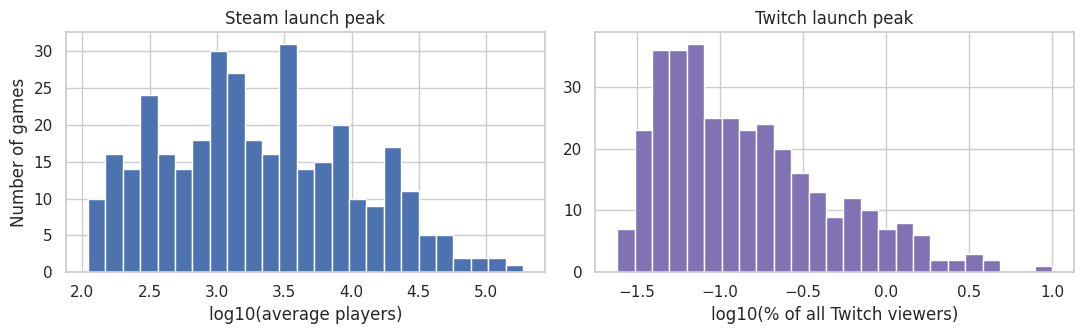

Correlation between log Steam peak and log Twitch peak: 0.66


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log10(games["steam_launch_peak"]), bins=25)
axes[0].set(title="Steam launch peak", xlabel="log10(average players)",
            ylabel="Number of games")
axes[1].hist(np.log10(games["twitch_launch_peak"] * 100), bins=25, color="C4")
axes[1].set(title="Twitch launch peak",
            xlabel="log10(% of all Twitch viewers)")
plt.tight_layout()
plt.show()

r = np.corrcoef(np.log(games["steam_launch_peak"]),
                np.log(games["twitch_launch_peak"]))[0, 1]
print("Correlation between log Steam peak and log Twitch peak:", round(r, 2))

Both launch sizes cover about three orders of magnitude, so we plotted them on a log scale, where they look roughly bell-shaped. Steam and Twitch launch sizes are fairly strongly related (correlation of the logs is about 0.66). Because sizes vary so much, we compare games using retention (each game compared to its own launch peak) instead of raw numbers, and we will use the log of launch size in our models.

### The typical lifecycle

This is the main picture for RQ1. On the left is the median Steam retention each month. On the right is the share of games still in the Twitch top 200 each month. We use the median because a few games grew a lot, which would pull the mean up.

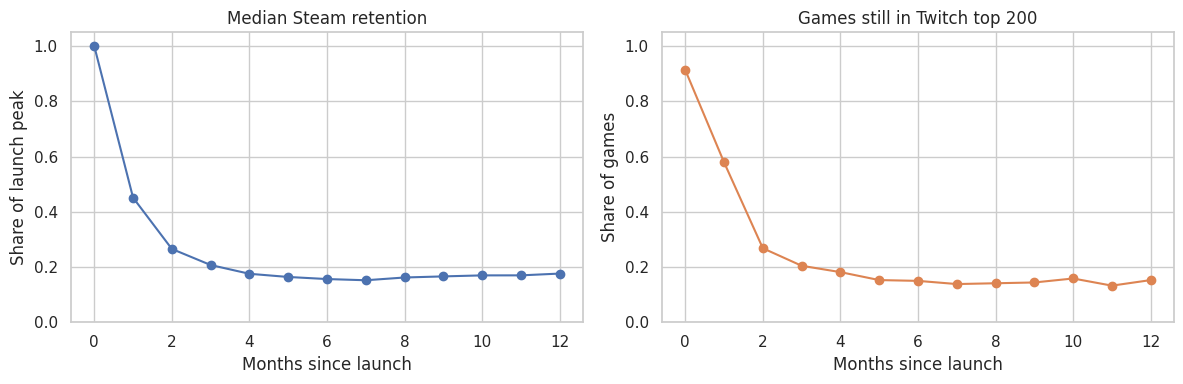

,Median Steam retention,Share still on Twitch list
months_since_launch,,
1,0.45,0.58
3,0.21,0.20
6,0.16,0.15
12,0.18,0.15


In [ ]:
by_month = lifecycle.groupby("months_since_launch")
steam_median = by_month["steam_retention"].median()
share_listed = by_month["on_twitch_list"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(steam_median.index, steam_median, "o-")
axes[0].set(title="Median Steam retention", xlabel="Months since launch",
            ylabel="Share of launch peak", ylim=(0, 1.05))
axes[1].plot(share_listed.index, share_listed, "o-", color="C1")
axes[1].set(title="Games still in Twitch top 200",
            xlabel="Months since launch",
            ylabel="Share of games", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

lifecycle_table = pd.DataFrame({"Median Steam retention": steam_median,
                                "Share still on Twitch list": share_listed})
lifecycle_table.loc[[1, 3, 6, 12]].round(2)

The median game keeps only about 21% of its Steam launch-peak players by month 3, then levels off around 15 to 18%. Most of the drop happens in the first two to three months. Twitch falls off even faster: only 58% of games are still in the top 200 one month after launch, and only about 15% after six months.

### Steam vs. Twitch retention for the same game (month 3)

RQ1 asks whether Twitch interest fades faster than Steam interest for the same game. This plot only includes the games still in the top 200 at month 3, since those are the only ones where we know Twitch retention. Points below the dashed line are games where Twitch fell faster than Steam.

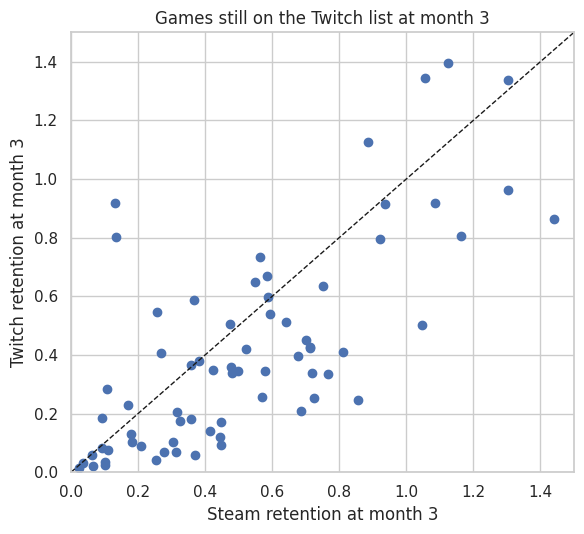

Games still listed at month 3: 71 of 347
Of those, share where Twitch fell faster than Steam: 73%
Median Steam retention at month 3: still listed 0.48, off the list 0.18


In [ ]:
m3 = games.dropna(subset=["steam_ret_m3"])
listed = m3["on_twitch_m3"] == True

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(m3.loc[listed, "steam_ret_m3"], m3.loc[listed, "twitch_ret_m3"])
ax.plot([0, 1.5], [0, 1.5], "k--", lw=1)
ax.set(xlim=(0, 1.5), ylim=(0, 1.5),
       xlabel="Steam retention at month 3",
       ylabel="Twitch retention at month 3",
       title="Games still on the Twitch list at month 3")
plt.tight_layout()
plt.show()

print(f"Games still listed at month 3: {listed.sum()} of {len(m3)}")
still = m3[listed]
below = (still["twitch_ret_m3"] < still["steam_ret_m3"]).mean()
print(f"Of those, share where Twitch fell faster than Steam: {below:.0%}")
print("Median Steam retention at month 3:",
      f"still listed {m3.loc[listed, 'steam_ret_m3'].median():.2f},",
      f"off the list {m3.loc[~listed, 'steam_ret_m3'].median():.2f}")

Even among the games that stayed on the list, about 73% fell faster on Twitch than on Steam, and the two kinds of retention tend to move together. These are also the strongest games: their median Steam retention at month 3 is 0.48, compared to 0.18 for games that already left the list. Since the games we can see here are the best-case games, Twitch probably fades even faster for a typical game.

### Is launch size related to how long a game stays on Twitch?

If bigger launches simply stay on the list longer, we need to account for launch size in our models.

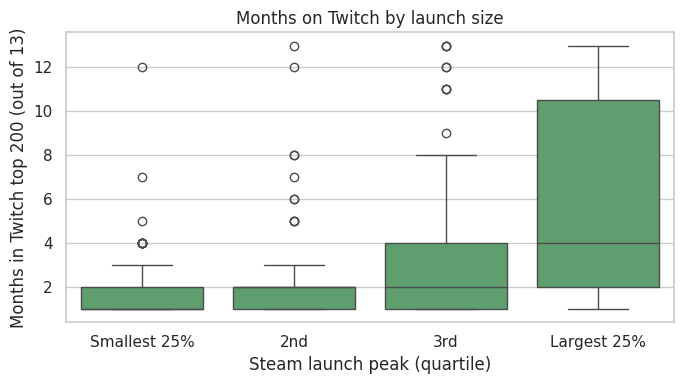

Median months on list by quartile:
steam_launch_peak
Smallest 25%    1.0
2nd             2.0
3rd             2.0
Largest 25%     4.0

Correlation between log Steam launch peak and months on list: 0.48


In [ ]:
quartile = pd.qcut(games["steam_launch_peak"], 4,
                   labels=["Smallest 25%", "2nd", "3rd", "Largest 25%"])
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=quartile, y=games["months_on_twitch_list"], ax=ax, color="C2")
ax.set(xlabel="Steam launch peak (quartile)",
       ylabel="Months in Twitch top 200 (out of 13)",
       title="Months on Twitch by launch size")
plt.tight_layout()
plt.show()

print("Median months on list by quartile:")
by_quartile = games.groupby(quartile, observed=True)["months_on_twitch_list"]
print(by_quartile.median().to_string())
r = np.corrcoef(np.log(games["steam_launch_peak"]),
                games["months_on_twitch_list"])[0, 1]
print("\nCorrelation between log Steam launch peak and months on list:",
      round(r, 2))

Bigger launches stay in the Twitch top 200 longer, and the correlation is positive. The median game is only on the list for 2 of 13 months, while games in the largest quartile stay twice as long (a median of 4 months). Part of this is expected: a game that starts far above the cutoff has more room to fall before it drops out. So our models of Twitch staying power need to control for launch size.

### How many games are multiplayer or free-to-play?

Here we only count how many games are in each group. We do not compare their retention yet, because that is what our preregistered analyses will test.

In [ ]:
for col in ["multiplayer", "free_to_play"]:
    print(games[col].value_counts(dropna=False).to_string(), "\n")

multiplayer
1.0    173
0.0    155
NaN     19 

free_to_play
0.0    310
1.0     23
NaN     14 



The multiplayer and single-player groups are about the same size (173 and 155 games), which is good for comparing them. Only 23 games are free-to-play, so any result about free-to-play games will be much less certain. 14 of our games aren't in the Steam Dataset 2025 at all (they were probably removed from Steam), and 5 more only have game-mode labels in other languages, so 19 games are missing a game-mode value and will be left out of the preregistered analyses.

### What EDA changed

- We only follow games for 12 months after launch, because the Twitch data covers January 2016 to September 2024 and most of our usable games launched between 2016 and 2018.
- We measure Twitch interest as viewer share instead of raw viewers, since total Twitch viewing more than tripled over this period.
- Because games drop out of the top 200 data once their viewership falls, we added months on the Twitch list as a Twitch measure we always know, and we use it as our main Twitch outcome.
- We updated our data description to explain the AppID cutoff and why most games are from 2016 to 2018, and narrowed RQ2 to multiplayer and free-to-play games so we only need two columns from the Steam Dataset 2025.
- For modeling, retention is very right-skewed (the median is about 0.2, but a few games are above 10), so we will use log retention, and we will control for launch size.

## Preregistration of Analyses

Both analyses use the `multiplayer` and `free_to_play` columns we added from the Steam Dataset 2025. We have only counted these groups and have not looked at how they relate to our outcomes. We will report both results whether or not they are significant.

### Preregistration Statement 1

**Hypothesis:** Multiplayer games keep a larger share of their Steam launch-peak players six months after launch than games without multiplayer.

Multiplayer games give players reasons to come back (friends, ranked play, new opponents), while many single-player games are finished once the story ends.

**Analysis:** Run a linear regression where the output is `log(steam_ret_m6)` and the inputs are:
- `multiplayer`: 1 if the game's Steam categories include multiplayer, 0 if not
- `free_to_play`: 1 if the game is free, 0 if not, since free games have no price barrier
- `log(steam_launch_peak)`: since EDA showed launch size is related to later outcomes

We use the log of retention because EDA showed retention is very right-skewed. We will test whether **β_multiplayer > 0**.

### Preregistration Statement 2

**Hypothesis:** Multiplayer games stay in the Twitch top 200 for more months in their first year than single-player games, even after accounting for how big their Twitch launch was.

Many viewers watch a story game once, to see it or to decide whether to buy it, while multiplayer games keep producing new matches worth watching.

**Analysis:** Run a linear regression where the output is `months_on_twitch_list` (1 to 13) and the inputs are:
- `multiplayer`: same as above
- `log(twitch_launch_peak)`: since EDA showed bigger launches stay listed longer
- `free_to_play`

We will test whether **β_multiplayer > 0**.

## Questions for Reviewers

1. Both of our preregistered analyses test the same variable (`multiplayer`), once for Steam players and once for months on Twitch. We chose this to keep the project focused, but we weren't sure if it makes our two analyses too similar. Would it be better to change one of them to test something different?
2. Only 23 of our games are free-to-play. Is that enough to keep `free_to_play` as a control in our regressions, or would it make our results less reliable?
3. We count a game as multiplayer if it has any multiplayer category, even local co-op or a small online mode. We talked about only counting online multiplayer, since that is what we think brings players back, but it would make the groups smaller. Which do you think makes more sense?
4. Twitch retention is missing once a game drops out of the top 200, so we use months on the Twitch list as our main Twitch outcome. Does this seem like a fair way to measure how long a game stays popular on Twitch?
5. Most of our games launched in 2016 to 2018 because of the AppID cutoff in the Steam data. Should we look for newer Steam data before Phase III, or just say our results only apply to that time period?